# XÂY DỰNG MÔ HÌNH CNN NHẬN DIỆN CẢM XÚC KHUÔN MẶT

## Mục tiêu và định hướng thực hiện

**Mục tiêu tổng quát:** Xây dựng và huấn luyện mô hình mạng nơ-ron tích chập ($Convolutional Neural Network$ – $CNN$) bằng $PyTorch$ để nhận diện cảm xúc thể hiện trên khuôn mặt từ ảnh đầu vào.

**Các mục tiêu cụ thể:**
- Chuẩn bị và tổ chức dữ liệu $FER2013$ theo các tập $Training$, $PublicTest$ và $PrivateTest$.
- Xây dựng quy trình tiền xử lý ảnh, tăng cường dữ liệu và nạp dữ liệu theo $batch$.
- Thiết kế kiến trúc $CNN$ phù hợp với ảnh khuôn mặt $grayscale$ có kích thước $48 \times 48$.
- Huấn luyện mô hình, theo dõi $Loss$ và $Accuracy$ trên tập huấn luyện và tập $validation$.
- Đánh giá mô hình trên tập $test$ bằng các chỉ số và công cụ trực quan, trong đó có $Confusion Matrix$.
- Quan sát các bộ lọc ở lớp tích chập đầu tiên nhằm minh họa đặc trưng mà $CNN$ học được ở tầng đầu.

## Tổng quan về bài toán và dữ liệu

Bài toán FER ($Facial Expression Recognition$) hướng đến việc phân loại cảm xúc của con người thông qua hình ảnh khuôn mặt. Notebook sử dụng bộ dữ liệu **$FER2013$**, trong đó ảnh đầu vào được biểu diễn dưới dạng ảnh xám kích thước $48 \times 48$ $pixel$.

Mô hình thực hiện phân loại đa lớp với **7 trạng thái cảm xúc**:
- Angry – Tức giận
- Disgust – Ghê tởm
- Fear – Sợ hãi
- Happy – Vui vẻ
- Sad – Buồn
- Surprise – Ngạc nhiên
- Neutral – Bình thường

Dữ liệu được chia theo trường `Usage` thành các tập `Training`, `PublicTest` và `PrivateTest`. Trong quy trình bên dưới, `Training` được dùng để cập nhật trọng số, `PublicTest` đóng vai trò tập $validation$ để theo dõi quá trình học, còn `PrivateTest` được giữ lại cho bước đánh giá cuối cùng.

## 1. Chuẩn bị môi trường và dữ liệu

### 1.1. Import các thư viện cần thiết

Các thư viện được sử dụng gồm $PyTorch$ để xây dựng và huấn luyện mạng $CNN$, $Torchvision$ để biến đổi ảnh, cùng các thư viện xử lý dữ liệu và trực quan hóa. Một số công cụ bổ trợ được dùng để tóm tắt kiến trúc và minh họa đồ thị mô hình.

In [71]:
!pip install torchinfo
!pip install torchviz

In [72]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
from torchinfo import summary
from torchviz import make_dot

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report
import seaborn as sns
from sklearn.metrics import confusion_matrix
import seaborn as sns
from PIL import Image as PILImage
from IPython.display import Image, display
import os

In [73]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Thiết bị đang sử dụng: {device}")

Thiết bị đang sử dụng: cuda


### 1.2. Khởi tạo cấu trúc thư mục lưu trữ

Tạo các thư mục riêng để quản lý dữ liệu, trọng số mô hình, kết quả huấn luyện và hình ảnh trực quan. Cách tổ chức này giúp các sản phẩm đầu ra được lưu trữ nhất quán, thuận tiện cho việc kiểm tra và sử dụng lại.

In [74]:
os.makedirs('data', exist_ok=True)
os.makedirs('models', exist_ok=True)
os.makedirs('outputs', exist_ok=True)
os.makedirs('figures', exist_ok=True)

### 1.3. Đọc bộ dữ liệu $FER2013$

Đọc tệp dữ liệu $CSV$ từ đường dẫn được thiết lập. Notebook ưu tiên `data/fer2013.csv`; nếu tệp này không tồn tại, chương trình chuyển sang kiểm tra `data/icml_face_data.csv`. Sau khi đọc, tên cột được loại bỏ khoảng trắng thừa để hạn chế lỗi khi truy xuất.

In [75]:
csv_path = 'data/fer2013.csv'
if not os.path.exists(csv_path):
    csv_path = 'data/icml_face_data.csv'

In [76]:
df = pd.read_csv(csv_path)
df.columns = df.columns.str.strip()

### 1.4 Ánh xạ nhãn cảm xúc

Các nhãn cảm xúc ban đầu được mã hóa bằng số nguyên từ 0 đến 6. Từ điển `emotion_labels` ánh xạ các mã này sang tên cảm xúc tương ứng, giúp kết quả thống kê và biểu đồ dễ đọc, dễ diễn giải hơn.

In [77]:
emotion_labels = {0: 'Angry', 1: 'Disgust', 2: 'Fear', 3: 'Happy', 4: 'Sad', 5: 'Surprise', 6: 'Neutral'}
df['emotion_name'] = df['emotion'].map(emotion_labels)

In [78]:
print(f"Tổng số lượng mẫu: {len(df):,}")
print("\nThống kê số lượng mẫu theo từng tập (Usage):")
print(df['Usage'].value_counts())

Tổng số lượng mẫu: 35,887

Thống kê số lượng mẫu theo từng tập (Usage):
Usage
Training       28709
PublicTest      3589
PrivateTest     3589
Name: count, dtype: int64


### 1.5. Khảo sát phân bố dữ liệu

Trước khi huấn luyện, cần kiểm tra quy mô dữ liệu và số lượng mẫu thuộc từng tập dữ liệu. Biểu đồ phân bố theo cảm xúc và `Usage` hỗ trợ nhận diện sự chênh lệch số lượng mẫu giữa các lớp, từ đó cung cấp bối cảnh khi phân tích kết quả phân loại.

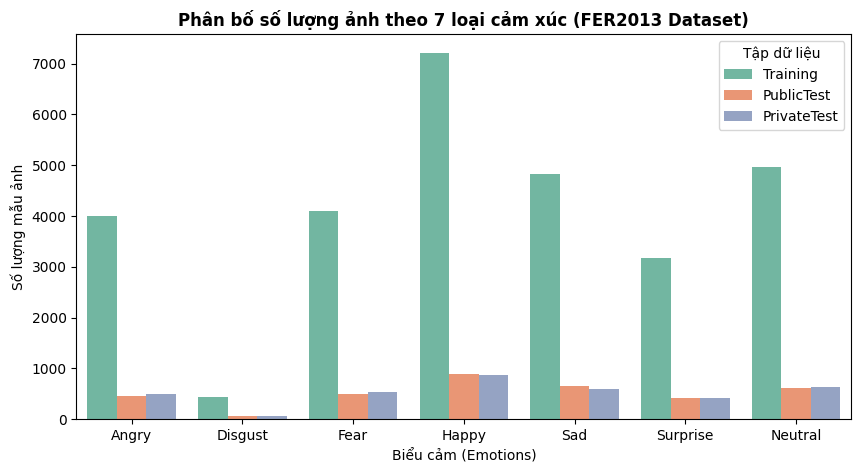

Đã lưu biểu đồ phân bố vào thư mục: figures/dataset_distribution.png


In [79]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='emotion_name', hue='Usage', order=emotion_labels.values(), palette='Set2')
plt.title('Phân bố số lượng ảnh theo 7 loại cảm xúc (FER2013 Dataset)', fontsize=12, fontweight='bold')
plt.xlabel('Biểu cảm (Emotions)', fontsize=10)
plt.ylabel('Số lượng mẫu ảnh', fontsize=10)
plt.legend(title='Tập dữ liệu')
plt.savefig('figures/dataset_distribution.png', dpi=300, bbox_inches='tight')
plt.show()
print("Đã lưu biểu đồ phân bố vào thư mục: figures/dataset_distribution.png")

### 1.6. Xây dựng lớp $Custom Dataset$ cho $PyTorch$

Lớp $Dataset$ tùy chỉnh chịu trách nhiệm lọc dữ liệu theo tập, chuyển chuỗi $pixel$ thành ma trận ảnh và trả về cặp (ảnh, nhãn). Việc đóng gói thao tác này giúp $DataLoader$ có thể truy xuất dữ liệu thống nhất trong suốt quá trình huấn luyện và đánh giá.

In [80]:
class FastFER2013Dataset(Dataset):
    def __init__(self, dataframe, split='Training', transform=None):
        # Lọc dữ liệu theo split
        sub_df = dataframe[dataframe['Usage'] == split].reset_index(drop=True)
        self.transform = transform

        print(f"Đang tiền xử lý dữ liệu cho tập {split}...")
        # Chuyển toàn bộ chuỗi pixel thành mảng numpy 3 chiều 1 lần duy nhất lúc khởi tạo
        # Giúp loại bỏ hoàn toàn độ trễ khi lấy từng mẫu trong quá trình train
        pixels_list = sub_df['pixels'].values
        images = []
        for p_str in pixels_list:
            img_arr = np.array(p_str.split(), dtype=np.uint8).reshape(48, 48)
            images.append(img_arr)

        self.images = np.array(images)
        self.labels = sub_df['emotion'].values

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        image_array = self.images[idx]
        image = PILImage.fromarray(image_array)
        label = int(self.labels[idx])

        if self.transform:
            image = self.transform(image)

        return image, label

### 1.7. $Data Augmentation$ và chuẩn hóa ảnh

Các phép biến đổi ngẫu nhiên như lật ngang, xoay và cắt ảnh được áp dụng cho tập $Training$ nhằm tăng tính đa dạng của dữ liệu đầu vào và giảm nguy cơ $overfitting$. Tập $validation$ và $test$ sử dụng phép biến đổi đánh giá, tránh tạo ra biến thiên ngẫu nhiên không cần thiết trong quá trình đo lường.

In [81]:
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.RandomCrop(48, padding=4),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

### 1.8. Khởi tạo các tập dữ liệu $Training$, $Validation$ và $Test$

Từ $Dataset$ tùy chỉnh, khởi tạo ba đối tượng dữ liệu tương ứng với `Training`, `PublicTest` và `PrivateTest`. Mỗi tập được gắn với pipeline biến đổi phù hợp với vai trò của nó trong quy trình.

In [82]:
train_dataset = FastFER2013Dataset(df, split='Training', transform=train_transform)
val_dataset   = FastFER2013Dataset(df, split='PublicTest', transform=test_transform)
test_dataset  = FastFER2013Dataset(df, split='PrivateTest', transform=test_transform)

Đang tiền xử lý dữ liệu cho tập Training...
Đang tiền xử lý dữ liệu cho tập PublicTest...
Đang tiền xử lý dữ liệu cho tập PrivateTest...


### 1.9. Xây dựng $DataLoader$

$DataLoader$ chia dữ liệu thành các $batch$ để mô hình xử lý theo từng nhóm mẫu. Tập $Training$ được xáo trộn thứ tự mẫu khi nạp; các tập $validation$ và $test$ giữ thứ tự ổn định để hỗ trợ đánh giá và đối chiếu kết quả.

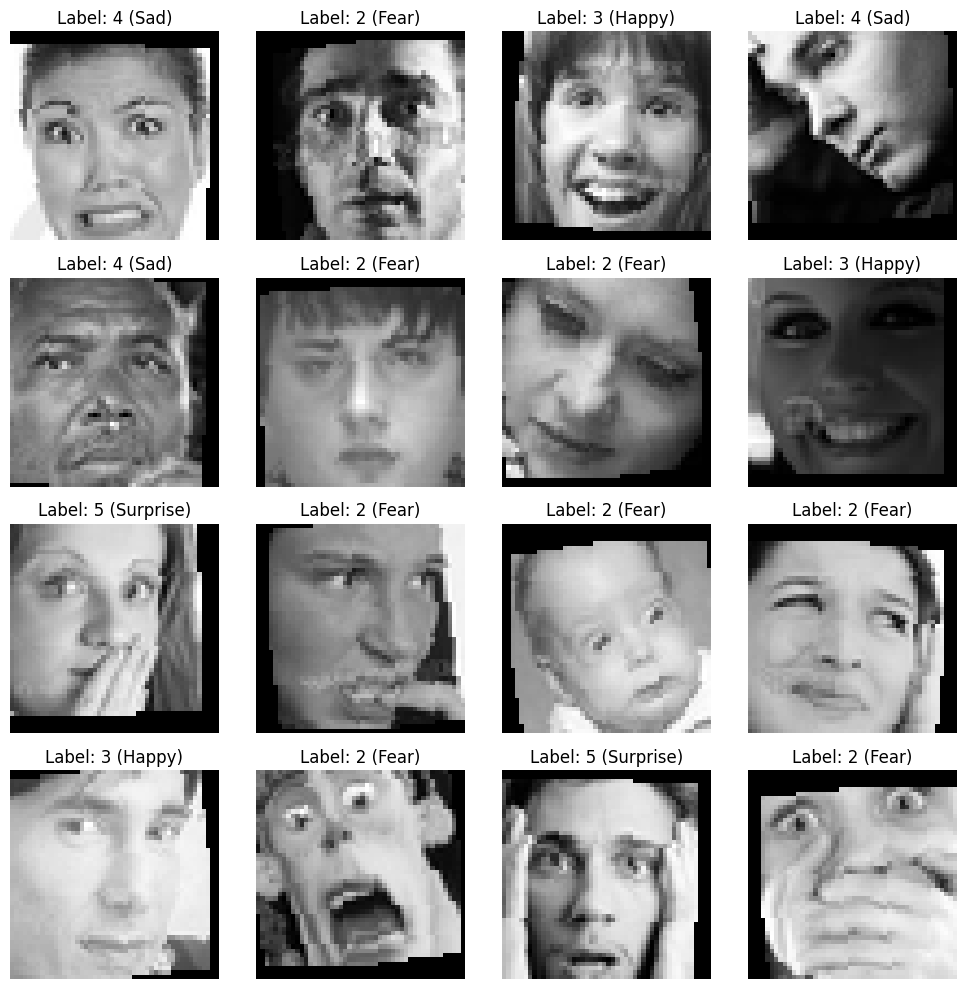

Đã trực quan hóa và lưu 16 ảnh mẫu vào thư mục: figures/sample_fer_images.png


In [83]:
BATCH_SIZE = 64
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

images, labels = next(iter(train_loader))

# Thiết lập khung hiển thị lưới 4x4 (16 ảnh mẫu)
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
for i, ax in enumerate(axes.flatten()):
    if i < len(images):
        # Chuyển đổi tensor ảnh về dạng numpy array và đảo ngược phép Normalize (về lại khoảng [0, 1])
        img = images[i].numpy().squeeze() # Bỏ chiều channel (1, 48, 48) -> (48, 48)
        img = (img * 0.5) + 0.5            # Đưa pixel từ [-1, 1] về [0, 1]

        # Lấy nhãn tương ứng
        label_idx = labels[i].item()
        label_name = emotion_labels[label_idx]

        # Hiển thị ảnh dạng grayscale
        ax.imshow(img, cmap='gray')
        ax.title.set_text(f"Label: {label_idx} ({label_name})")
        ax.axis('off')

plt.tight_layout()
plt.savefig('figures/sample_fer_images.png', dpi=300, bbox_inches='tight')
plt.show()

print("Đã trực quan hóa và lưu 16 ảnh mẫu vào thư mục: figures/sample_fer_images.png")

## 2. Xây dựng kiến trúc mô hình $CNN$ và kiểm tra

Ở phần này, mô hình $CNN$ được thiết kế để trích xuất đặc trưng không gian từ ảnh khuôn mặt và ánh xạ các đặc trưng đó sang 7 lớp cảm xúc. Sau khi khởi tạo, mô hình được kiểm tra bằng cách thống kê số lượng tham số, mô phỏng kích thước $tensor$ qua các tầng và lưu lại trọng số khởi tạo.

In [84]:
class EmotionCNN(nn.Module):
    def __init__(self, num_classes=7):
        super(EmotionCNN, self).__init__()

        # --- KHỐI TÍCH CHẬP 1 (BLOCK 1) ---
        # Mục đích: Trích xuất các đặc trưng biên, góc, cấu trúc khuôn mặt cơ bản ở độ phân giải cao (48x48)
        self.block1 = nn.Sequential(
            # Conv2d(in_channels=1, out_channels=32, kernel_size=3, padding=1) -> Giữ nguyên kích thước 48x48
            nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32), # Chuẩn hóa batch giúp mô hình hội tụ nhanh và ổn định hơn
            nn.ReLU(),          # Hàm kích hoạt phi tuyến tính

            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.MaxPool2d(kernel_size=2, stride=2), # Giảm kích thước không gian xuống một nửa: 48x48 -> 24x24
            nn.Dropout(0.25)                      # Dropout 25% các nơ-ron ngẫu nhiên để chống Overfitting
        )

        # --- KHỐI TÍCH CHẬP 2 (BLOCK 2) ---
        # Mục đích: Trích xuất các đặc trưng phức tạp hơn (hình dáng mắt, miệng, cung mày,...)
        self.block2 = nn.Sequential(
            nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),

            nn.MaxPool2d(kernel_size=2, stride=2), # Giảm kích thước: 24x24 -> 12x12

            nn.Conv2d(in_channels=128, out_channels=128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),

            nn.MaxPool2d(kernel_size=2, stride=2), # Giảm kích thước: 12x12 -> 6x6
            nn.Dropout(0.25)
        )

        # --- CÁC LỚP FULLY CONNECTED (CLASSIFIER) ---
        # Đầu vào: 128 channels x 6 (chiều cao) x 6 (chiều rộng) = 4612 features
        self.classifier = nn.Sequential(
            nn.Linear(128 * 6 * 6, 512),
            nn.ReLU(),
            nn.Dropout(0.5),                    # Dropout 50% ở lớp Fully Connected để tránh phụ thuộc tuyến tính
            nn.Linear(512, num_classes)         # Đầu ra trả về 7 logits (tương ứng với 7 lớp cảm xúc)
        )

    def forward(self, x):
        # Truyền qua Block 1
        x = self.block1(x)

        # Truyền qua Block 2
        x = self.block2(x)

        # Duỗi thẳng (Flatten) tensor từ dạng 4D (Batch, Channels, Height, Width) về dạng 2D (Batch, Features)
        x = x.view(x.size(0), -1)

        # Truyền qua các lớp Fully Connected để phân loại
        out = self.classifier(x)
        return out

In [85]:
model = EmotionCNN(num_classes=7).to(device)

# Tính tổng số tham số (đưa thông số này vào phần báo cáo của nhóm)
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"KIẾN TRÚC CNN")
print(f"Tổng số tham số huấn luyện (Trainable Parameters): {total_params:,}")

# Kiểm tra chiều dữ liệu qua từng bước (đảm bảo không bị lỗi shape mismatch)
dummy_input = torch.randn(64, 1, 48, 48).to(device) # Giả lập 1 batch gồm 64 ảnh xám 48x48
print(f"- Kích thước tensor đầu vào (Input): {dummy_input.shape}")

out_block1 = model.block1(dummy_input)
print(f"- Kích thước sau Block 1 (Conv + MaxPool): {out_block1.shape}") # Kỳ vọng: [64, 64, 24, 24]

out_block2 = model.block2(out_block1)
print(f"- Kích thước sau Block 2 (Conv + MaxPool): {out_block2.shape}") # Kỳ vọng: [64, 128, 6, 6]

flatten_out = out_block2.view(out_block2.size(0), -1)
print(f"- Kích thước sau khi Flatten: {flatten_out.shape}")             # Kỳ vọng: [64, 4608]

final_output = model(dummy_input)
print(f"- Kích thước đầu ra cuối cùng (Output Logits): {final_output.shape}") # Kỳ vọng: [64, 7]

KIẾN TRÚC CNN
Tổng số tham số huấn luyện (Trainable Parameters): 2,604,359
- Kích thước tensor đầu vào (Input): torch.Size([64, 1, 48, 48])
- Kích thước sau Block 1 (Conv + MaxPool): torch.Size([64, 64, 24, 24])
- Kích thước sau Block 2 (Conv + MaxPool): torch.Size([64, 128, 6, 6])
- Kích thước sau khi Flatten: torch.Size([64, 4608])
- Kích thước đầu ra cuối cùng (Output Logits): torch.Size([64, 7])


### Thành phần và luồng xử lý của mô hình

| Thành phần | Cấu hình / kích thước | Vai trò |
|---|---|---|
| **Input** | Ảnh xám `1 × 48 × 48` | Tiếp nhận ảnh khuôn mặt đã chuẩn hóa |
| **Block 1** | `Conv2d: 1 → 32 → 64`, BatchNorm, ReLU, MaxPool | Học các đặc trưng ban đầu như cạnh, đường nét và vùng sáng tối |
| **Block 2** | `Conv2d: 64 → 128 → 128`, BatchNorm, ReLU, MaxPool | Học các đặc trưng phức tạp hơn từ những vùng trên khuôn mặt |
| **Regularization** | Dropout `0.25` ở các block; Dropout `0.5` ở classifier | Giảm sự phụ thuộc vào một số neuron, hỗ trợ hạn chế overfitting |
| **Classifier** | Flatten `128 × 6 × 6 = 4.608` đặc trưng; Linear `4608 → 512 → 7` | Kết hợp đặc trưng và tạo điểm số cho 7 lớp cảm xúc |
| **Output** | Vector gồm 7 logits | Mỗi phần tử tương ứng với một lớp: Angry, Disgust, Fear, Happy, Sad, Surprise và Neutral |

**Luồng kích thước tensor:**

`1 × 48 × 48` → Block 1: `64 × 24 × 24` → Block 2: `128 × 6 × 6` → Flatten: `4608` → Fully Connected: `512` → Output: `7`.

> **Lưu ý:** Các giá trị kích thước trên mô tả một ảnh đầu vào (không tính chiều batch). Lớp cuối trả về logits; khi cần xác suất dự đoán có thể áp dụng Softmax ở bước suy luận. Với `CrossEntropyLoss` của PyTorch, không cần tự áp dụng Softmax trước khi tính loss.


Mô hình sử dụng hai khối tích chập để xây dựng biểu diễn đặc trưng theo từng cấp độ. Ở các tầng đầu, mạng có thể học những mẫu thị giác đơn giản; qua các tầng sâu hơn, các đặc trưng được kết hợp để biểu diễn những cấu trúc có ý nghĩa hơn đối với việc phân biệt cảm xúc. Batch Normalization hỗ trợ ổn định quá trình học, ReLU tạo tính phi tuyến, còn Max Pooling giảm kích thước không gian và chi phí tính toán.

Sau bước trích xuất đặc trưng, tensor được làm phẳng thành vector 4.608 chiều và đưa qua các lớp kết nối đầy đủ để tạo ra 7 logits. Nhãn dự đoán là lớp có logit lớn nhất. Số lượng tham số và kích thước đầu ra thực tế được kiểm tra bằng torchinfo.summary ở ô lệnh tiếp theo.

In [86]:
# summary giúp mô phỏng đầu vào (Batch size, Channel, Height, Width) qua từng lớp
summary(model, input_size=(64, 1, 48, 48))

Layer (type:depth-idx)                   Output Shape              Param #
EmotionCNN                               [64, 7]                   --
├─Sequential: 1-1                        [64, 64, 24, 24]          --
│    └─Conv2d: 2-1                       [64, 32, 48, 48]          320
│    └─BatchNorm2d: 2-2                  [64, 32, 48, 48]          64
│    └─ReLU: 2-3                         [64, 32, 48, 48]          --
│    └─Conv2d: 2-4                       [64, 64, 48, 48]          18,496
│    └─BatchNorm2d: 2-5                  [64, 64, 48, 48]          128
│    └─ReLU: 2-6                         [64, 64, 48, 48]          --
│    └─MaxPool2d: 2-7                    [64, 64, 24, 24]          --
│    └─Dropout: 2-8                      [64, 64, 24, 24]          --
├─Sequential: 1-2                        [64, 128, 6, 6]           --
│    └─Conv2d: 2-9                       [64, 128, 24, 24]         73,856
│    └─BatchNorm2d: 2-10                 [64, 128, 24, 24]         256
│   

In [87]:
os.makedirs('models', exist_ok=True)
initial_model_path = 'models/initial_model_architecture.pth'
torch.save(model.state_dict(), initial_model_path)
print(f"\nĐã lưu cấu trúc và trọng số khởi tạo tại: {initial_model_path}")


Đã lưu cấu trúc và trọng số khởi tạo tại: models/initial_model_architecture.pth


Đã vẽ và lưu sơ đồ kiến trúc mạng dạng hình ảnh tại: figures/cnn_architecture_graph.png


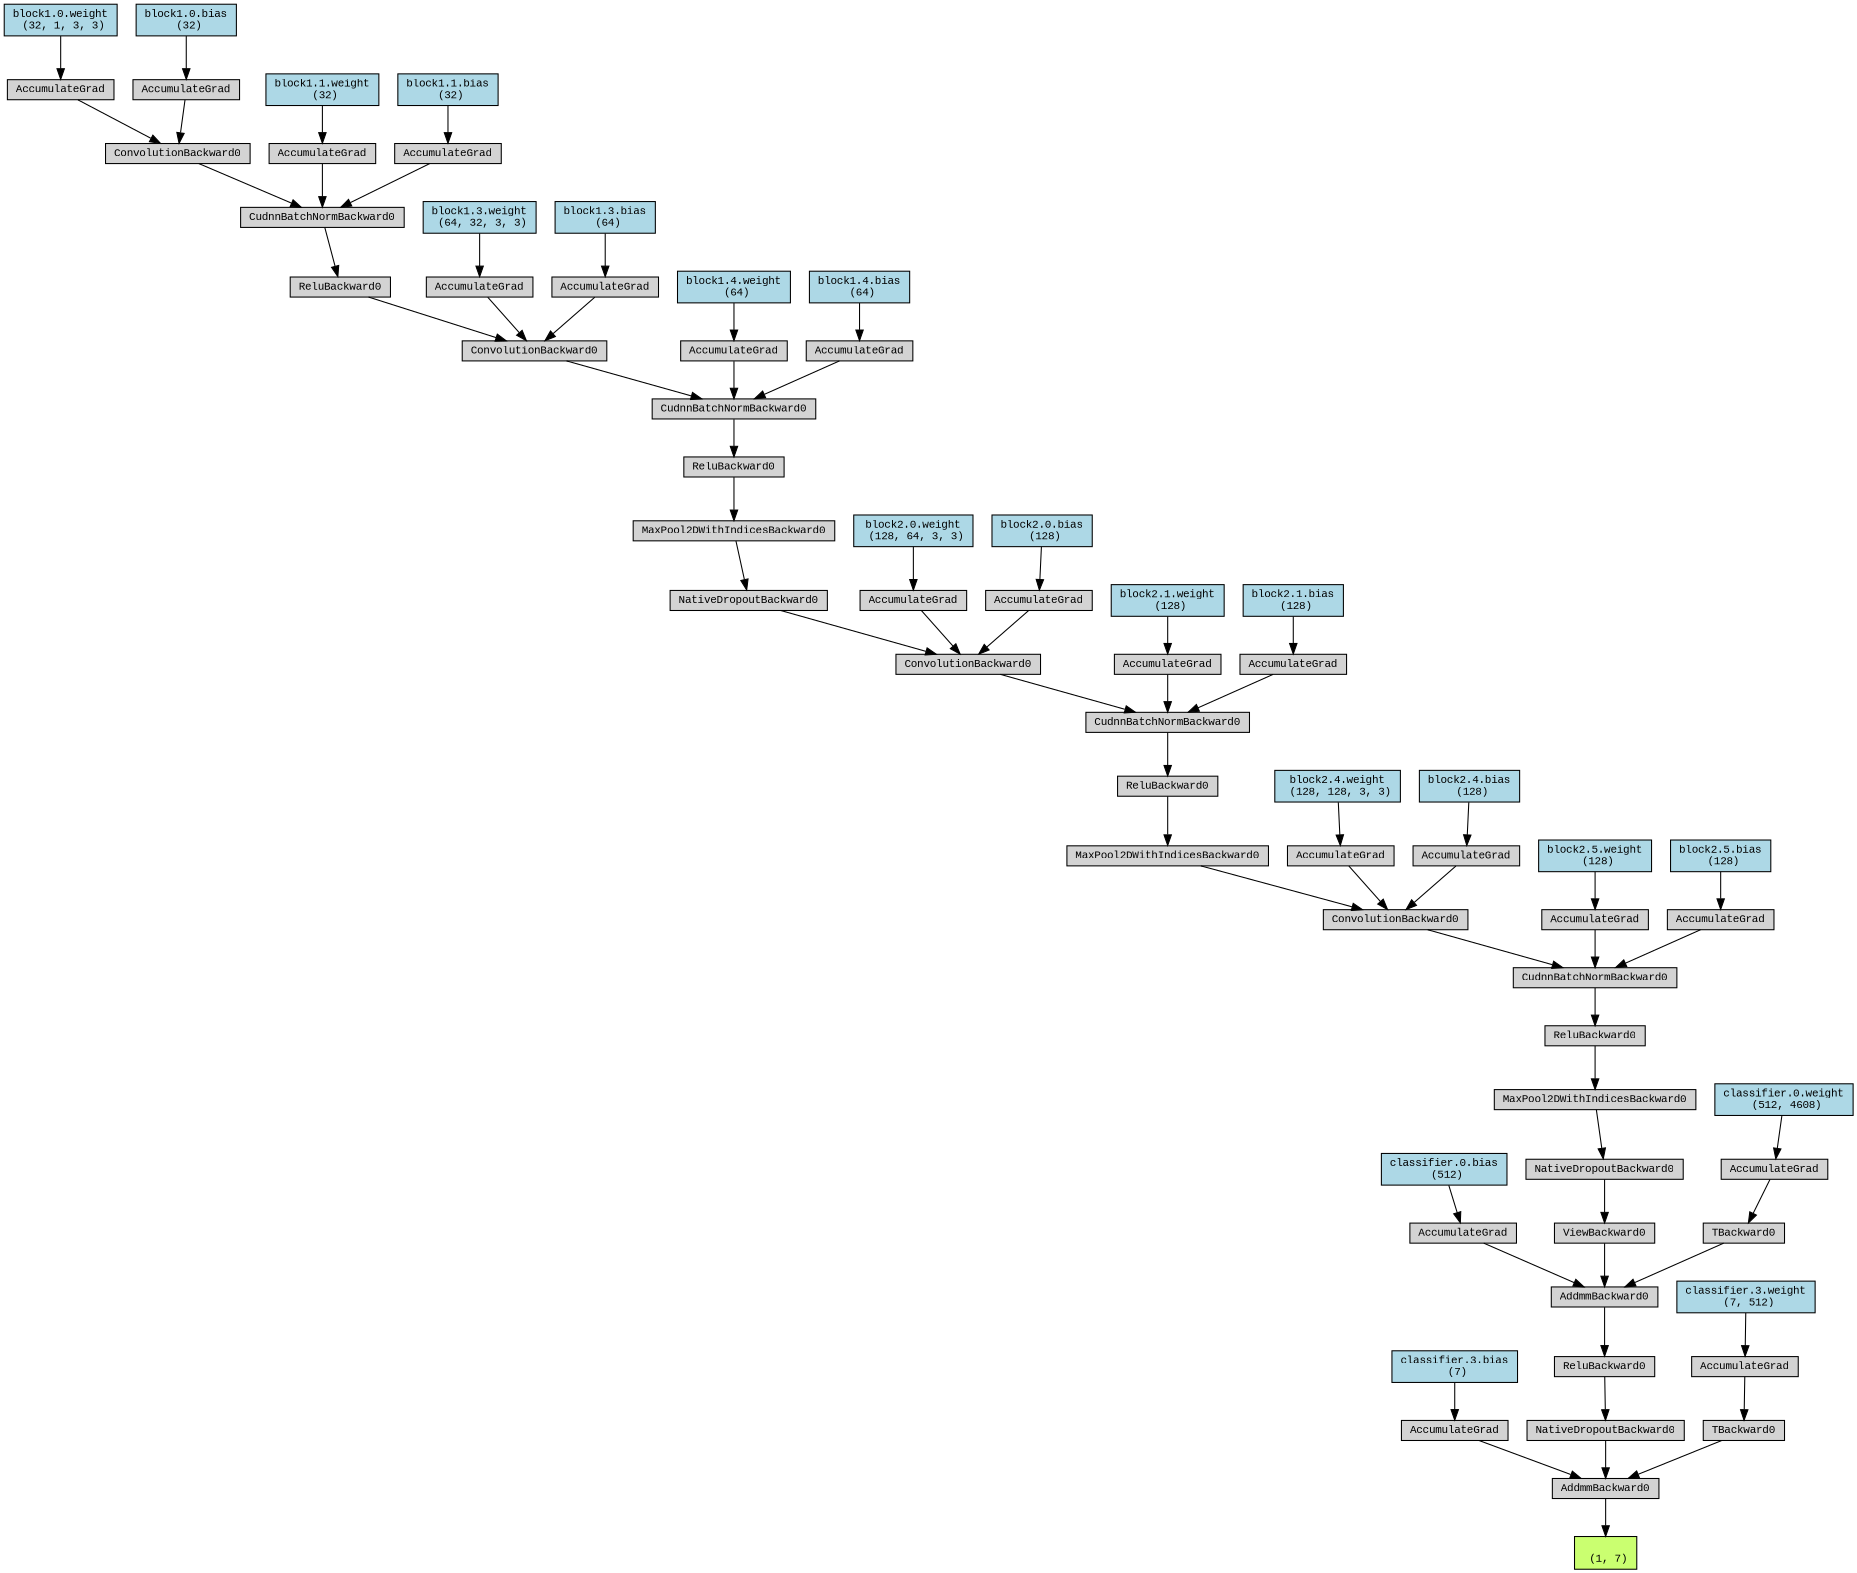

In [88]:
os.makedirs('figures', exist_ok=True)

# Tạo một tensor giả lập để vẽ đồ thị mạng
dummy_input = torch.randn(1, 1, 48, 48).to(device)
output = model(dummy_input)

# Vẽ đồ thị kết nối giữa các tầng Conv, Pool, Linear,...
dot = make_dot(output, params=dict(model.named_parameters()))
dot.format = 'png'
dot.directory = 'figures'
dot_path = dot.render('cnn_architecture_graph')
print(f"Đã vẽ và lưu sơ đồ kiến trúc mạng dạng hình ảnh tại: {dot_path}")

display(Image(filename='figures/cnn_architecture_graph.png'))